# Методы оптимизации в машинном обучении: отчёт по практическому заданию

В этом отчёте реализованы и исследованы **градиентный спуск** и **метод Ньютона**.

**Что лежит в папке с заданием:**
* `optimization.py` — линейный поиск (постоянный шаг, Армихо, Вульф), градиентный спуск, метод Ньютона;
* `oracles.py` — квадратичная функция, оракул логистической регрессии, конечные разности;
* `plot_trajectory_2d.py` — функции для рисования линий уровня и траекторий (выданы вместе с заданием, не менялись);
* `data/` — наборы данных *w8a*, *gisette*, *real-sim*.

**Содержание отчёта**
1. Вывод формул для логистической регрессии (задание 6)
2. Проверка оракула конечными разностями (задание 7)
3. Эксперимент 1: траектории градиентного спуска на 2D-квадратичных функциях (задание 3)
4. Эксперимент 2: число итераций от числа обусловленности и размерности (задание 4)
5. Эксперимент 3: градиентный спуск против метода Ньютона на реальных данных (задание 8)

In [1]:
import time
import warnings
import numpy as np
import scipy.sparse
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import load_svmlight_file

import oracles
import optimization
from plot_trajectory_2d import plot_levels, plot_trajectory

warnings.filterwarnings('ignore')                       # убираем предупреждения scipy о линейном поиске, чтобы не мусорили вывод
plt.rcParams.update({'font.size': 12, 'lines.linewidth': 3})   # шрифт покрупнее и линии потолще, как просят в задании
SEED = 42                                               # фиксируем seed, чтобы результаты воспроизводились

# 1. Формулы для логистической регрессии (задание 6)

Есть $m$ объектов: $a_i \in \mathbb{R}^n$ — признаки, $b_i \in \{-1, 1\}$ — классы. Минимизируем
$$f(x) = \frac{1}{m}\sum_{i=1}^m \ln\left(1 + e^{-b_i \langle a_i, x\rangle}\right) + \frac{\lambda}{2}\|x\|_2^2 .$$

**Обозначения.** $A \in \mathbb{R}^{m\times n}$ — матрица, у которой $i$-я строка равна $a_i^T$; $b \in \mathbb{R}^m$ — вектор классов; $\odot$ — поэлементное умножение; $\mathbf 1_m$ — вектор из единиц;
$$z := b \odot (Ax) \in \mathbb{R}^m, \qquad z_i = b_i\langle a_i, x\rangle, \qquad \sigma(t) = \frac{1}{1+e^{-t}} .$$
Скалярные функции ($\ln$, $\exp$, $\sigma$) применяются к векторам поэлементно.

**Функция.** Сумма $\sum_i \ln(1 + e^{-z_i})$ — это скалярное произведение вектора из единиц на вектор $\ln(1 + e^{-z})$:
$$\boxed{f(x) = \frac{1}{m}\,\mathbf 1_m^T \ln\left(1 + e^{-z}\right) + \frac{\lambda}{2}\|x\|_2^2}$$

**Градиент.**
* Производная по $z_i$: $\dfrac{d}{dz_i}\ln(1+e^{-z_i}) = \dfrac{-e^{-z_i}}{1+e^{-z_i}} = -\dfrac{1}{1+e^{z_i}} = -\sigma(-z_i)$.
* Внутренняя функция: $\nabla_x z_i = b_i a_i$.
* По правилу цепочки: $\nabla f(x) = -\dfrac1m\sum_i \sigma(-z_i)\, b_i\, a_i + \lambda x$. Сумма $\sum_i c_i a_i$ равна $A^T c$, поэтому
$$\boxed{\nabla f(x) = -\frac{1}{m}\,A^T\big(b \odot \sigma(-z)\big) + \lambda x}$$

**Гессиан.**
* Производная сигмоиды: $\sigma'(t) = \sigma(t)(1-\sigma(t))$. Значит $\dfrac{d}{dz_i}\sigma(-z_i) = -\sigma(-z_i)\big(1-\sigma(-z_i)\big) = -s_i$, где $s := \sigma(-z)\odot(1-\sigma(-z))$.
* Тогда $\nabla_x\big[\sigma(-z_i)\big] = -s_i\, b_i\, a_i$, и
$$\nabla^2 f(x) = -\frac1m\sum_i b_i a_i\,\big(-s_i b_i a_i\big)^T + \lambda I_n = \frac1m\sum_i s_i\, b_i^2\, a_i a_i^T + \lambda I_n .$$
* Так как $b_i^2 = 1$, а $\sum_i s_i a_i a_i^T = A^T\,\mathrm{Diag}(s)\,A$:
$$\boxed{\nabla^2 f(x) = \frac{1}{m}\,A^T\,\mathrm{Diag}(s)\,A + \lambda I_n}$$

Так как $s_i > 0$ и $\lambda > 0$, гессиан положительно определён, то есть функция сильно выпукла и метод Ньютона с разложением Холецкого применим.

# 2. Проверка оракула конечными разностями (задание 7)

Проверяем, что аналитические `grad` и `hess` из `LogRegL2Oracle` совпадают с численными приближениями `grad_finite_diff` и `hess_finite_diff`. Данные случайные и маленькие ($m=50$, $n=5$), проверка идёт и для обычной матрицы, и для разреженной `csr_matrix`, в трёх случайных точках.

In [2]:
rng = np.random.RandomState(SEED)
m_test, n_test = 50, 5
A_dense = rng.normal(size=(m_test, n_test))             # случайная матрица признаков
b_test = np.where(rng.rand(m_test) > 0.5, 1.0, -1.0)    # случайные метки -1 / +1

rows = []
for matrix_type, A_ in [('dense np.array', A_dense), ('sparse csr_matrix', scipy.sparse.csr_matrix(A_dense))]:
    oracle = oracles.LogRegL2Oracle(A_, b_test, regcoef=0.1)
    for trial in range(3):
        x = rng.normal(size=n_test)                     # случайная пробная точка
        g_err = np.max(np.abs(oracle.grad(x) - oracles.grad_finite_diff(oracle.func, x)))
        h_err = np.max(np.abs(oracle.hess(x) - oracles.hess_finite_diff(oracle.func, x)))
        rows.append([matrix_type, trial + 1, g_err, h_err])

table = pd.DataFrame(rows, columns=['тип матрицы A', 'точка №', 'max|grad - grad_fd|', 'max|hess - hess_fd|'])
print(table.to_string(index=False, float_format=lambda v: '{:.2e}'.format(v)))

    тип матрицы A  точка №  max|grad - grad_fd|  max|hess - hess_fd|
   dense np.array        1             2.00e-08             4.30e-06
   dense np.array        2             1.72e-08             4.37e-06
   dense np.array        3             1.13e-08             2.97e-06
sparse csr_matrix        1             2.02e-08             3.67e-06
sparse csr_matrix        2             2.82e-08             4.83e-06
sparse csr_matrix        3             2.00e-08             5.65e-06


**Вывод.** Аналитический градиент и гессиан совпадают с разностными приближениями: ошибка градиента порядка $10^{-8}$, ошибка гессиана порядка $10^{-6}$. Это и ожидаемая точность формул: у градиента шаг $\varepsilon_1 = 10^{-8}$, у гессиана $\varepsilon_2 = 10^{-5}$, а сама разностная формула даёт ошибку примерно порядка шага. Для плотной и для разреженной матрицы результаты одинаковые, значит оракул написан правильно и работает с обоими типами матриц.

# 3. Эксперимент 1: траектории градиентного спуска на 2D-квадратичных функциях (задание 3)

**Что делаем.** Берём три двумерные функции $f(x) = \frac12\langle Ax, x\rangle$ (минимум в нуле, $b=0$). Матрица $A = Q\,\mathrm{Diag}(\lambda_1,\lambda_2)\,Q^T$, где $Q$ — поворот на 30°, чтобы оси эллипсов не совпадали с осями координат. Меняется только число обусловленности $\kappa = \lambda_{\max}/\lambda_{\min}$:

| функция | собственные числа | $\kappa$ |
|---|---|---|
| $f_1$ | 1 и 2 | 2 |
| $f_2$ | 1 и 10 | 10 |
| $f_3$ | 1 и 100 | 100 |

Для каждой функции запускаем градиентный спуск из трёх начальных точек (они отмечены кружками) и с тремя стратегиями выбора шага:
* **Constant** — постоянный шаг $c = 1/L$, где $L = \lambda_{\max}$ (для квадратичной функции это безопасный шаг);
* **Armijo** — дробление шага, $c_1 = 10^{-4}$, $\alpha_0 = 1$, адаптивный (стартуем с $2\alpha_{k-1}$);
* **Wolfe** — сильные условия Вульфа, $c_1 = 10^{-4}$, $c_2 = 0.9$.

Остальные параметры: относительная точность `tolerance=1e-5`, `max_iter=10000`.

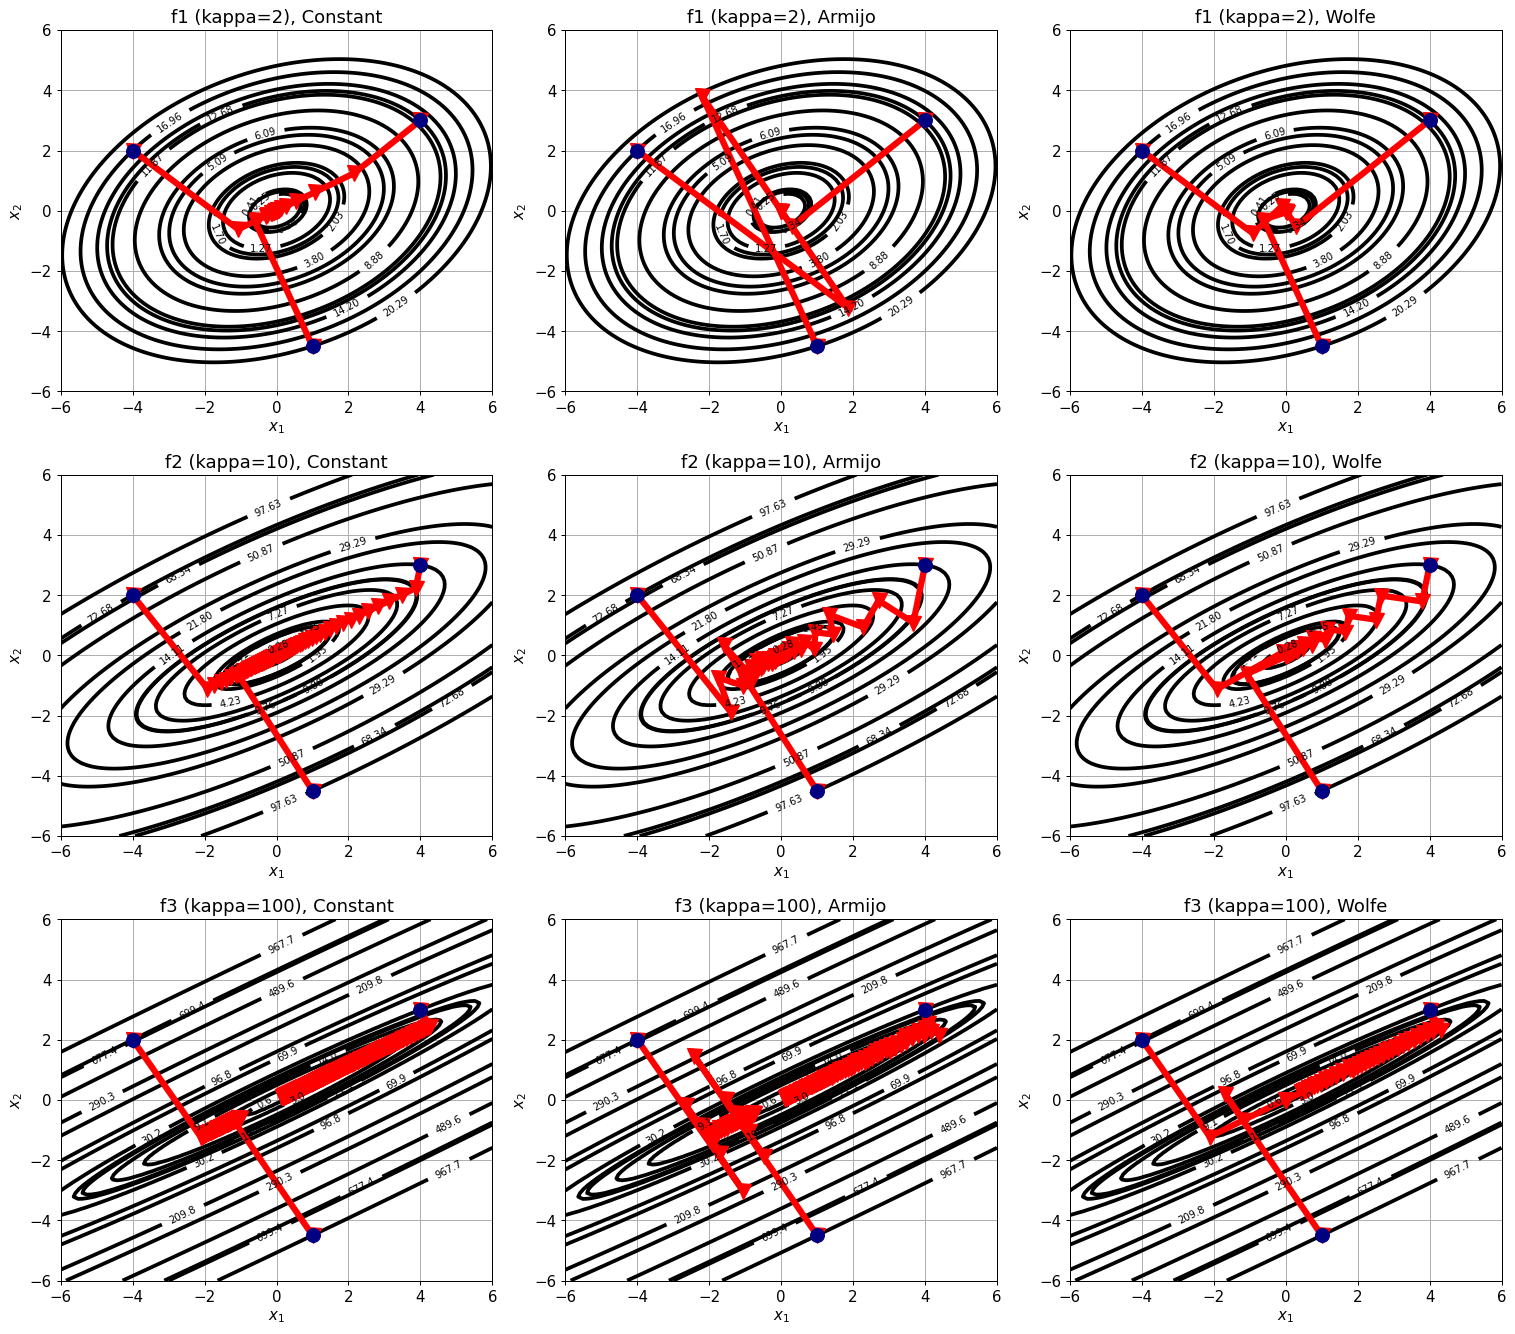

In [3]:
def make_quadratic(eigenvalues, angle=np.pi / 6):
    # Собираем A = Q * Diag(eigenvalues) * Q^T, где Q - матрица поворота на угол angle
    c, s = np.cos(angle), np.sin(angle)
    Q = np.array([[c, -s], [s, c]])
    A = Q @ np.diag(eigenvalues) @ Q.T
    return A

functions = {'f1 (kappa=2)': [1, 2], 'f2 (kappa=10)': [1, 10], 'f3 (kappa=100)': [1, 100]}
start_points = [np.array([4.0, 3.0]), np.array([-4.0, 2.0]), np.array([1.0, -4.5])]
strategies = ['Constant', 'Armijo', 'Wolfe']

fig, axes = plt.subplots(3, 3, figsize=(17, 15))
iterations = {}                                         # сюда запишем число итераций для таблицы

for row, (name, eigs) in enumerate(functions.items()):
    A = make_quadratic(eigs)
    oracle = oracles.QuadraticOracle(A, np.zeros(2))
    L = max(eigs)                                       # наибольшее собственное число
    # уровни линий: доли от значений функции в стартовых точках, чтобы линии проходили через интересную область
    f_start = [oracle.func(p) for p in start_points]
    levels = sorted(set(np.round([f * q for f in f_start for q in (0.02, 0.1, 0.3, 0.7, 1.0)], 6)))
    for col, strategy in enumerate(strategies):
        plt.sca(axes[row, col])                         # рисуем в нужной клетке сетки графиков
        plot_levels(oracle.func, xrange=[-6, 6], yrange=[-6, 6], levels=levels)
        options = {'method': strategy}
        if strategy == 'Constant':
            options['c'] = 1.0 / L                      # постоянный шаг 1/L
        iters = []
        for p in start_points:
            x_star, msg, history = optimization.gradient_descent(oracle, p, trace=True, line_search_options=options)
            plot_trajectory(oracle.func, history['x'])
            plt.scatter(*p, s=120, c='navy', zorder=5)  # отмечаем стартовую точку
            iters.append(len(history['x']) - 1)         # число шагов = число записей минус одна (стартовая)
        iterations[(name, strategy)] = iters
        axes[row, col].set_title('{}, {}'.format(name, strategy))
        axes[row, col].set_xlabel('$x_1$')
        axes[row, col].set_ylabel('$x_2$')
        axes[row, col].set_xlim(-6, 6)
        axes[row, col].set_ylim(-6, 6)
plt.tight_layout()
plt.show()

In [4]:
# Таблица: сколько итераций потребовалось из каждой из трёх стартовых точек
table = pd.DataFrame({s: {f: iterations[(f, s)] for f in functions} for s in strategies})
print('Число итераций до остановки (для стартовых точек (4,3), (-4,2), (1,-4.5)):')
print(table.to_string())

Число итераций до остановки (для стартовых точек (4,3), (-4,2), (1,-4.5)):
                    Constant         Armijo       Wolfe
f1 (kappa=2)       [9, 7, 6]      [2, 2, 2]   [2, 3, 3]
f2 (kappa=10)   [51, 29, 22]   [25, 15, 14]  [28, 3, 3]
f3 (kappa=100)  [325, 74, 1]  [161, 50, 18]  [63, 3, 2]


**Что изображено.** Чёрные линии — линии уровня функции (эллипсы), красные стрелки — траектории градиентного спуска из трёх начальных точек (синие кружки). Строки — функции с $\kappa = 2, 10, 100$, столбцы — стратегии выбора шага.

**Выводы.**
1. **Число обусловленности.** При $\kappa = 2$ эллипсы почти круглые, и метод приходит в минимум за 2–9 шагов. При $\kappa = 10$ нужно уже 14–51 шаг, а при $\kappa = 100$ — до 325 шагов. Эллипсы вытягиваются в узкую «долину», антиградиент смотрит не на минимум, а почти перпендикулярно долине, и метод идёт зигзагом от одной стенки долины к другой, медленно продвигаясь вдоль её дна. Чем больше $\kappa$, тем длиннее зигзаг и тем больше итераций.
2. **Начальная точка.** От неё тоже сильно зависит результат. Точка, которая лежит почти на «короткой» оси эллипса (то есть вдоль направления с большим собственным числом), решается за несколько шагов, а точка вдоль «длинной» оси ползёт долго. Особый случай: для $f_3$ с постоянным шагом из точки $(1, -4.5)$ метод остановился за 1 итерацию. Это не чудо: точка лежит почти точно вдоль собственного вектора с наибольшим собственным числом, шаг $1/L$ почти обнуляет градиент, и критерий остановки (он относительный, то есть сравнивает с очень большим начальным градиентом) срабатывает сразу.
3. **Стратегия шага.** *Постоянный шаг* $1/L$ работает надёжно (идёт без «перелётов»), но нужно заранее знать $L$, а для плохо обусловленной функции он слишком осторожный. *Армихо* не требует знания $L$, но траектории заметно «дёргаются»: из-за деления шага пополам и удвоения на следующем шаге он то слишком большой, то слишком маленький. *Вульф* чаще всего делает самые умные шаги и в нескольких случаях выигрывает по числу итераций (например, для $f_3$: 63, 3, 2 против 161, 50, 18 у Армихо), но не всегда (для $f_2$ из точки $(4, 3)$: 28 против 25 у Армихо) и стоит дороже за один шаг, так как вызывает оракул несколько раз.

# 4. Эксперимент 2: число итераций в зависимости от $\kappa$ и $n$ (задание 4)

**Что делаем.** Исследуем $T(n,\kappa)$ — сколько итераций градиентного спуска нужно для сходимости на квадратичной задаче $f(x) = \frac12\langle Ax, x\rangle - \langle b, x\rangle$.

**Как генерируем задачу.**
* $A = \mathrm{Diag}(a)$ — диагональная матрица (в формате `scipy.sparse.diags`), диагональные элементы случайные из $[1,\kappa]$, причём принудительно $\min a = 1$, $\max a = \kappa$, значит число обусловленности ровно $\kappa$;
* $b$ — случайный вектор из стандартного нормального распределения;
* старт $x_0 = 0$, критерий остановки (1.1) с `tolerance=1e-4`, линейный поиск — Wolfe (по умолчанию), `max_iter=100000`.

**Сетка.** $\kappa$ — 10 значений на логарифмической сетке от 1 до 1000; $n \in \{10, 100, 1000, 10000\}$; для каждой пары $(n,\kappa)$ по 5 независимых случайных задач. Для каждого $n$ все 5 кривых рисуются одним цветом.

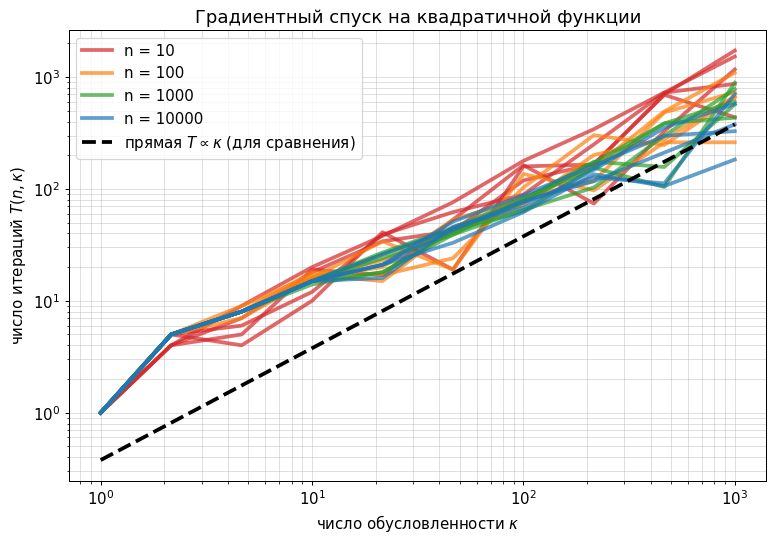

In [5]:
def make_problem(n, kappa, rng):
    a = rng.uniform(1, kappa, size=n)                   # случайные диагональные элементы из [1, kappa]
    a[0], a[-1] = 1.0, kappa                            # принудительно min = 1, max = kappa
    A = scipy.sparse.diags(a)                           # разреженная диагональная матрица
    b = rng.normal(size=n)                              # случайный вектор b
    return oracles.QuadraticOracle(A, b)

kappas = np.logspace(0, 3, 10)                          # 10 чисел обусловленности от 1 до 1000
ns = [10, 100, 1000, 10000]
n_repeats = 5
colors = {10: 'tab:red', 100: 'tab:orange', 1000: 'tab:green', 10000: 'tab:blue'}

rng = np.random.RandomState(SEED)
T = {}                                                  # T[(n, повтор)] = список числа итераций по сетке kappa
for n in ns:
    for rep in range(n_repeats):
        T[(n, rep)] = []
        for kappa in kappas:
            oracle = make_problem(n, kappa, rng)
            x_star, msg, history = optimization.gradient_descent(
                oracle, np.zeros(n), tolerance=1e-4, max_iter=100000, trace=True)
            assert msg == 'success', (n, kappa, msg)    # убеждаемся, что метод действительно сошёлся
            T[(n, rep)].append(len(history['func']) - 1)

plt.figure(figsize=(10, 6.5))
for n in ns:
    for rep in range(n_repeats):
        plt.plot(kappas, T[(n, rep)], color=colors[n], alpha=0.7, label='n = {}'.format(n) if rep == 0 else None)
ref = np.median([T[(10000, r)][-1] for r in range(n_repeats)])
plt.plot(kappas, ref * kappas / kappas[-1], 'k--', label=r'прямая $T \propto \kappa$ (для сравнения)')
plt.xscale('log'); plt.yscale('log')
plt.xlabel(r'число обусловленности $\kappa$'); plt.ylabel('число итераций $T(n, \\kappa)$')
plt.title('Градиентный спуск на квадратичной функции')
plt.grid(True, which='both', alpha=0.4); plt.legend()
plt.show()

In [6]:
# Средние значения T по 5 запускам (строки - kappa, столбцы - n)
mean_table = pd.DataFrame({'n = {}'.format(n): [np.mean([T[(n, r)][i] for r in range(n_repeats)]) for i in range(len(kappas))]
                           for n in ns}, index=['{:.1f}'.format(k) for k in kappas])
mean_table.index.name = 'kappa'
print(mean_table.round(1).to_string())

        n = 10  n = 100  n = 1000  n = 10000
kappa                                       
1.0        1.0      1.0       1.0        1.0
2.2        4.4      5.0       5.0        5.0
4.6        6.2      8.0       8.0        8.0
10.0      15.8     16.6      14.8       15.0
21.5      33.8     21.8      22.6       21.0
46.4      50.4     36.4      41.6       43.4
100.0    141.6     94.6      73.4       74.4
215.4    199.6    174.8     151.6      137.8
464.2    634.6    352.2     266.0      215.8
1000.0  1144.4    682.4     655.6      433.4


**Что изображено.** По горизонтали число обусловленности $\kappa$, по вертикали число итераций $T(n,\kappa)$, обе оси в логарифмическом масштабе. Каждый цвет — своё $n$, пять кривых одного цвета — пять случайных задач. Чёрная пунктирная линия — прямая $T \propto \kappa$ для сравнения наклона.

**Выводы.**
1. **Зависимость от $\kappa$.** Число итераций растёт с ростом $\kappa$ примерно по степенному закону: на графике с логарифмическими осями кривые идут почти по прямой, наклон близок к наклону пунктирной линии (от $\kappa = 10$ до $\kappa = 1000$, то есть в 100 раз, число итераций вырастает в 30–70 раз). Это совпадает с теорией: для градиентного спуска на сильно выпуклой функции число итераций порядка $\kappa \cdot \ln(1/\varepsilon)$. При $\kappa = 1$ (все собственные числа равны) метод сходится за 1 шаг.
2. **Зависимость от $n$.** Размерность почти не влияет: кривые для $n = 100, 1000, 10000$ практически накладываются друг на друга, а теоретическая оценка вообще не содержит $n$. Чем больше $n$, тем меньше «разброс» между пятью запусками: при большом $n$ собственные числа равномерно заполняют отрезок $[1, \kappa]$ и результат усредняется, а при $n = 10$ на итог сильно влияет случайное расположение нескольких собственных чисел (красные кривые разбросаны и в среднем выше, при $\kappa = 1000$ в среднем 1144 итерации против 433 при $n = 10000$).
3. **Итог.** Скорость градиентного спуска определяется не размером задачи, а её обусловленностью. Именно поэтому на плохо обусловленных задачах нужны методы второго порядка (Ньютон) или предобусловливание.

# 5. Эксперимент 3: градиентный спуск и метод Ньютона на реальных данных (задание 8)

**Задача.** Обучаем логистическую регрессию с $\ell_2$-регуляризацией: $\lambda = 1/m$, начальная точка $x_0 = 0$. Оба метода запускаются с параметрами по умолчанию: `tolerance=1e-5`, линейный поиск Wolfe (`c1=1e-4`, `c2=0.9`), `max_iter=10000` у градиентного спуска и `max_iter=100` у метода Ньютона.

**Данные (LIBSVM).**

| набор | объектов $m$ | признаков $n$ | особенность |
|---|---|---|---|
| *w8a* | 49 749 | 300 | разреженная матрица |
| *gisette* | 6 000 | 5 000 | матрица почти полностью заполнена (99% ненулей) |
| *real-sim* | 72 309 | 20 958 | сильно разреженная матрица |

Для каждого набора строим два графика: значение функции от реального времени и $\|\nabla f(x_k)\|_2^2 / \|\nabla f(x_0)\|_2^2$ (логарифмическая шкала) от реального времени.

**Две договорённости, которые продиктованы вычислительными ресурсами** (расчёт шёл на машине с одним ядром и 3 ГБ памяти):
1. **gisette.** Матрица заполнена почти полностью, поэтому разреженный формат ничего не даёт, а вычисление гессиана через разреженные произведения занимает больше 4 минут за одну итерацию. Поэтому для gisette матрица переводится в плотный `np.array` (240 МБ), и оба метода работают с одной и той же плотной матрицей. Кроме того, градиентный спуск на gisette ограничен `GISETTE_GD_MAX_ITER = 1000` итерациями (на полные 10 000 ушло бы около часа). Чтобы запустить полный прогон, достаточно поставить 10000.
2. **real-sim.** Метод Ньютона там не запускается: гессиан — плотная матрица $n\times n$ при $n = 20958$, то есть около 3.5 ГБ только под сам гессиан (а для разложения Холецкого нужна ещё копия), что не помещается в память. Это не недоработка эксперимента, а сам по себе результат: он показывает слабую сторону метода Ньютона (оценки памяти и времени — ниже).

In [7]:
def run_experiment(A, b, gd_max_iter=10000, run_newton=True):
    m, n = A.shape
    oracle = oracles.LogRegL2Oracle(A, b, regcoef=1.0 / m)      # lambda = 1/m
    x0 = np.zeros(n)                                            # старт в нуле
    results = {}
    _, msg, hist = optimization.gradient_descent(oracle, x0, max_iter=gd_max_iter, trace=True)
    results['Градиентный спуск'] = (msg, hist)
    if run_newton:
        _, msg, hist = optimization.newton(oracle, x0, trace=True)
        results['Метод Ньютона'] = (msg, hist)
    return results

def plot_results(name, results):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    for label, (msg, h) in results.items():
        marker = 'o' if len(h['time']) < 15 else None            # у коротких траекторий рисуем точки на каждой итерации
        axes[0].plot(h['time'], h['func'], marker=marker, ms=8, label=label)
        rel = (np.array(h['grad_norm']) / h['grad_norm'][0]) ** 2   # относительный квадрат нормы градиента
        axes[1].plot(h['time'], rel, marker=marker, ms=8, label=label)
    axes[0].set_xlabel('время работы, с'); axes[0].set_ylabel('значение функции $f(x_k)$')
    axes[0].set_title(name + ': значение функции')
    axes[1].set_yscale('log')
    axes[1].set_xlabel('время работы, с'); axes[1].set_ylabel(r'$\|\nabla f(x_k)\|^2 / \|\nabla f(x_0)\|^2$')
    axes[1].set_title(name + ': относительный квадрат нормы градиента')
    for ax in axes:
        ax.grid(True, which='both', alpha=0.4); ax.legend()
    plt.tight_layout(); plt.show()

summary = []                                                    # общая таблица результатов
def add_summary(name, results):
    for label, (msg, h) in results.items():
        rel = (h['grad_norm'][-1] / h['grad_norm'][0]) ** 2
        summary.append([name, label, msg, len(h['func']) - 1, round(h['time'][-1], 2), h['func'][-1], rel])

### 5.1. Набор w8a

w8a: m = 49749, n = 300, ненулевых элементов: 579586


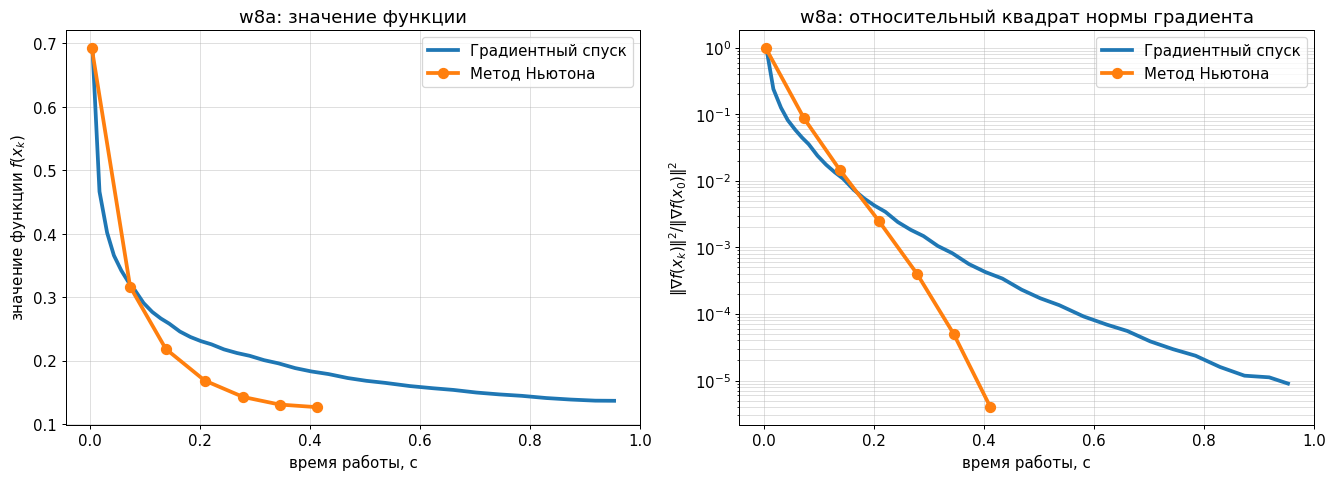

In [8]:
A_w8a, b_w8a = load_svmlight_file('data/w8a.txt')               # читаем файл формата svmlight (получаем csr_matrix)
print('w8a: m = {}, n = {}, ненулевых элементов: {}'.format(*A_w8a.shape, A_w8a.nnz))
res_w8a = run_experiment(A_w8a, b_w8a)
add_summary('w8a', res_w8a)
plot_results('w8a', res_w8a)

**Вывод по w8a.** Здесь $n = 300$ — признаков мало, поэтому гессиан маленький ($300\times 300$) и итерация Ньютона дешёвая. Метод Ньютона сошёлся за 6 итераций и 0.41 с, градиентный спуск — за 35 итераций и 0.95 с. То есть Ньютон выиграл даже по реальному времени, хотя одна итерация у него дороже (около 0.07 с против 0.03 с). Заметно, что в самом начале градиентный спуск быстрее снижает градиент (его итерации дешёвые), но потом он замедляется, а Ньютон идёт круто вниз (кривая почти прямая в логарифмической шкале, то есть сходимость очень быстрая).

### 5.2. Набор gisette

gisette: m = 6000, n = 5000, доля ненулевых: 99.1%


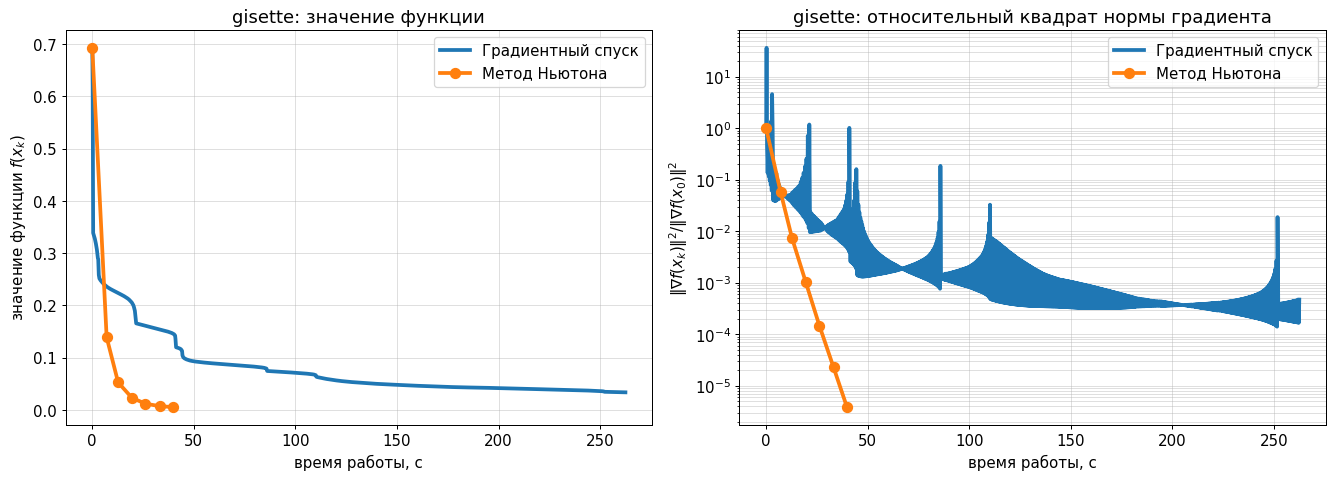

In [9]:
GISETTE_GD_MAX_ITER = 1000                                      # по умолчанию было бы 10000, см. пояснение выше
# Файл лежит в архиве .bz2, load_svmlight_file читает такие архивы напрямую, распаковывать не нужно.
A_gis, b_gis = load_svmlight_file('data/gisette_scale.bz2')
print('gisette: m = {}, n = {}, доля ненулевых: {:.1%}'.format(*A_gis.shape, A_gis.nnz / (A_gis.shape[0] * A_gis.shape[1])))
A_gis = A_gis.toarray()                                         # переводим в плотную матрицу (см. пояснение выше)
res_gis = run_experiment(A_gis, b_gis, gd_max_iter=GISETTE_GD_MAX_ITER)
add_summary('gisette', res_gis)
plot_results('gisette', res_gis)
del A_gis                                                       # освобождаем память

**Вывод по gisette.** Здесь признаков много ($n = 5000$), а объектов мало ($m = 6000$). Метод Ньютона сошёлся за 6 итераций и 39.8 с (одна итерация около 6.6 с: считается плотный гессиан $5000\times 5000$ и раскладывается по Холецкому). Градиентный спуск за 1000 итераций и 262 с (около 0.26 с на итерацию) **так и не дошёл** до нужной точности: относительный квадрат нормы градиента остановился на $4.7\cdot 10^{-4}$, а нужно $10^{-5}$. Значение функции у него тоже заметно хуже ($0.034$ против $0.005$). Причина: задача плохо обусловлена (маленький коэффициент регуляризации $\lambda = 1/m$), а градиентному спуску плохая обусловленность вредит, как мы видели в эксперименте 2. Ньютон учитывает кривизну и от этого почти не зависит.

Ещё одна особенность: на правом графике норма градиента у градиентного спуска не убывает монотонно, а «скачет» (всплески). Значение функции при этом падает, а вот норма градиента для сильно выпуклой функции монотонно убывать не обязана. Поэтому критерий остановки по норме градиента стоит применять осторожно.

### 5.3. Набор real-sim (только градиентный спуск)

real-sim: m = 72309, n = 20958, доля ненулевых: 0.24%
Память только под гессиан (плотная матрица n x n, float64): 3.51 ГБ
Примерное число операций на одно разложение Холецкого, n^3/3: 3.1e+12


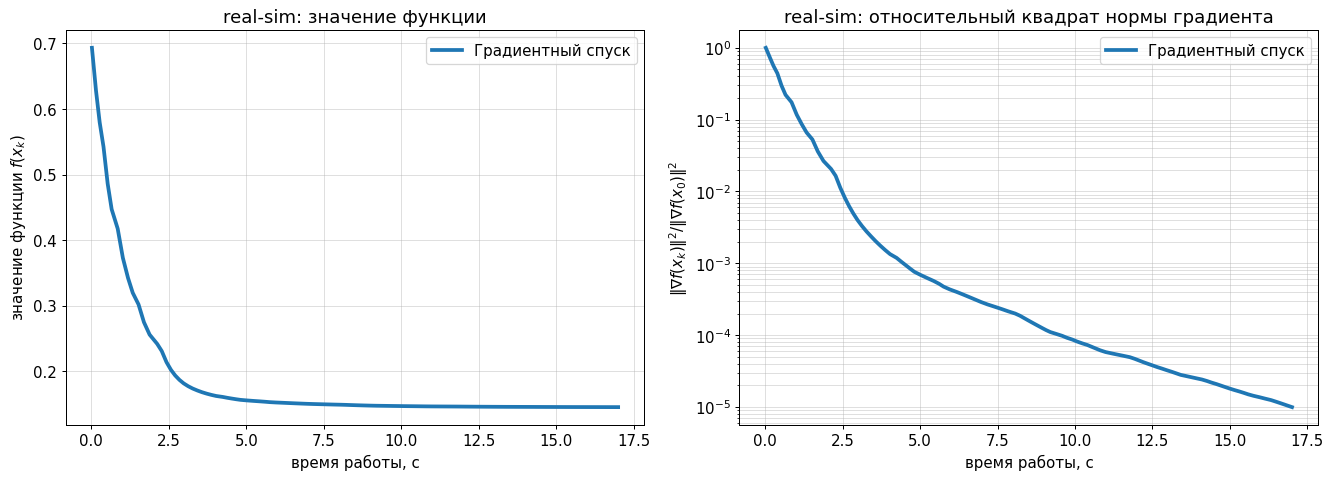

In [10]:
A_rs, b_rs = load_svmlight_file('data/real-sim.bz2')
m_rs, n_rs = A_rs.shape
print('real-sim: m = {}, n = {}, доля ненулевых: {:.2%}'.format(m_rs, n_rs, A_rs.nnz / (m_rs * n_rs)))
print('Память только под гессиан (плотная матрица n x n, float64): {:.2f} ГБ'.format(n_rs ** 2 * 8 / 1e9))
print('Примерное число операций на одно разложение Холецкого, n^3/3: {:.1e}'.format(n_rs ** 3 / 3))
res_rs = run_experiment(A_rs, b_rs, run_newton=False)
add_summary('real-sim', res_rs)
plot_results('real-sim', res_rs)

**Вывод по real-sim.** Градиентный спуск сошёлся за 103 итерации и около 17 с (матрица очень разреженная, всего 0.24% ненулевых элементов, поэтому каждая итерация дёшева). Метод Ньютона здесь не запускался: гессиан имеет размер $20958 \times 20958$ и требует 3.51 ГБ памяти только на сам гессиан, а разложение Холецкого потребовало бы ещё столько же и порядка $3\cdot 10^{12}$ операций на каждую итерацию. При большом числе признаков метод Ньютона просто неприменим, а градиентный спуск, которому нужно только $O(n)$ дополнительной памяти, работает без проблем.

### 5.4. Сводная таблица

In [11]:
summary_df = pd.DataFrame(summary, columns=['набор', 'метод', 'сообщение', 'итераций', 'время, с', 'f(x_final)', 'отн. ||grad||^2'])
print(summary_df.to_string(index=False, float_format=lambda v: '{:.3g}'.format(v)))

   набор             метод           сообщение  итераций  время, с  f(x_final)  отн. ||grad||^2
     w8a Градиентный спуск             success        35      0.95       0.137            9e-06
     w8a     Метод Ньютона             success         6      0.41       0.127         3.98e-06
 gisette Градиентный спуск iterations_exceeded      1000       262      0.0336         0.000473
 gisette     Метод Ньютона             success         6      39.8     0.00525         3.86e-06
real-sim Градиентный спуск             success       103        17       0.145         9.94e-06


### 5.5. Стоимость одной итерации и память

Обозначения: $m$ — число объектов, $n$ — число признаков. Для плотной матрицы $A$ (для разреженной $mn$ заменяется на число ненулевых элементов $\mathrm{nnz}(A)$).

| | градиентный спуск | метод Ньютона |
|---|---|---|
| вычисление функции и градиента | $O(mn)$ (два произведения матрицы на вектор: $Ax$ и $A^T w$) | $O(mn)$ |
| вычисление гессиана $\frac1m A^T\mathrm{Diag}(s)A$ | не нужно | $O(mn^2)$ |
| поиск направления | $O(n)$ (просто $-\nabla f$) | $O(n^3)$ (разложение Холецкого) |
| линейный поиск | несколько вычислений функции и градиента, $O(mn)$ каждое | то же |
| **итого за одну итерацию** | $O(mn)$ | $O(mn^2 + n^3)$ |
| **память** | $O(mn)$ на данные + $O(m+n)$ на векторы; дополнительно только $O(n)$ | $O(mn)$ на данные + $O(n^2)$ на гессиан |

Метод Ньютона делает мало итераций, но каждая дорогая, и ему нужна квадратная матрица $n\times n$ в памяти.

## Общие выводы по эксперименту 3

* **Метод Ньютона** делает очень мало итераций (6 на w8a и на gisette) и сходится быстро (квадратично вблизи решения), нечувствителен к плохой обусловленности. Но итерация дорогая: $O(mn^2 + n^3)$ по времени и $O(n^2)$ по памяти. Он выигрывает, когда признаков мало или умеренно много (w8a, $n=300$; gisette, $n=5000$ — выигрыш огромный, так как градиентный спуск не сошёлся вовсе).
* **Градиентный спуск** делает дешёвые итерации ($O(mn)$, а для разреженных данных $O(\mathrm{nnz}(A))$) и почти не требует памяти сверх самих данных, но на плохо обусловленных задачах сходится медленно. Он выигрывает, когда признаков очень много (real-sim, $n \approx 21\,000$) и гессиан просто не поместится в память, а также когда не нужна высокая точность (в начале обучения он быстрее снижает градиент).
* **Практический вывод:** при небольшом $n$ (до нескольких тысяч) разумно брать метод Ньютона, при очень большом $n$ — градиентный спуск (или его улучшения, а также квазиньютоновские методы, которые не хранят точный гессиан).